# Chapitre 8 - Exercices 8.1 à 8.6

Ce notebook traite les premiers exercices du chapitre 8, centrés sur les réseaux, la
détection des pannes et les horloges :

- **8.1** : pannes partielles à l'échelle d'un parc (calcul et simulation) ;
- **8.2** : relances, idempotence et durée de rétention des identifiants (raisonnement
  et mini-lab) ;
- **8.3** : choisir un délai d'expiration face à une queue lourde, seul ou à plusieurs
  observateurs (calcul) ;
- **8.4** : le détecteur phi accrual à la main (calcul et mini-lab) ;
- **8.5** : tampon de commutateur, perdre ou attendre (calcul et simulation) ;
- **8.6** : budget d'horloge, calcul NTP et serveur menteur (calcul).

In [1]:
import itertools
import math
import random
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.sim import Network, Node

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
rng = np.random.default_rng(0)

## Exercice 8.1 : pannes partielles à l'échelle d'un parc

**Énoncé.** Un service tourne sur 2 000 serveurs. Chaque serveur subit une panne
matérielle définitive en moyenne tous les 4 ans (MTTF), et il est par ailleurs
**transitoirement** injoignable ou trop lent 0,05 % du temps, indépendamment des autres.
Une requête d'utilisateur est éclatée en 40 sous-requêtes vers 40 serveurs différents et
n'aboutit que si toutes répondent. Le service reçoit 5 000 requêtes par seconde.

1. Combien de pannes définitives attend-on par jour ? Quelle est la probabilité de passer
   une semaine sans aucune ?
2. Quelle proportion des requêtes rencontre au moins un serveur en faute transitoire ?
   Combien de requêtes par jour cela représente-t-il ?
3. Chaque sous-requête peut désormais être servie par l'une de 2 répliques (on choisit
   une réplique saine). Que deviennent ces chiffres ? Et avec 3 répliques ?

**Rappels.** Panne partielle, « un sur un million, c'est tous les jours », probabilité
d'au moins une faute $1-(1-p)^n$ (cours 1, section 1 ; section *Faults and Partial
Failures*) ; pannes de Poisson (chapitre 1).

**Solution.**

*1.* Le taux de pannes du parc vaut $\lambda = 2000 / (4 \times 365) \approx 1{,}37$ par
jour : plus d'une panne définitive par jour. Les pannes forment un processus de Poisson,
donc $P(\text{aucune en 7 jours}) = e^{-7\lambda} \approx e^{-9{,}6} \approx 7 \times 10^{-5}$ :
une semaine sans panne n'arrive pour ainsi dire jamais.

*2.* Avec $p = 5 \times 10^{-4}$ et $n = 40$ : $1 - (1-p)^{40} \approx 40p = 2{,}0\,\%$ des
requêtes. Par jour : $5000 \times 86\,400 \times 0{,}0198 \approx 8{,}6$ millions de requêtes.

*3.* Une sous-requête n'échoue plus que si ses $r$ répliques sont toutes en faute :
$p^r$. Avec $r = 2$ : $p^2 = 2{,}5 \times 10^{-7}$, d'où $1-(1-p^2)^{40} \approx 10^{-5}$,
soit environ 4 300 requêtes par jour ; avec $r = 3$, environ 2 par jour. La redondance
multiplie l'**exposant** (si les fautes sont indépendantes, ce qu'il faut toujours
vérifier, chapitre 1).

pannes définitives : 1.37/jour ; semaines sans panne simulées : 0.00000 (théorie 0.00007)


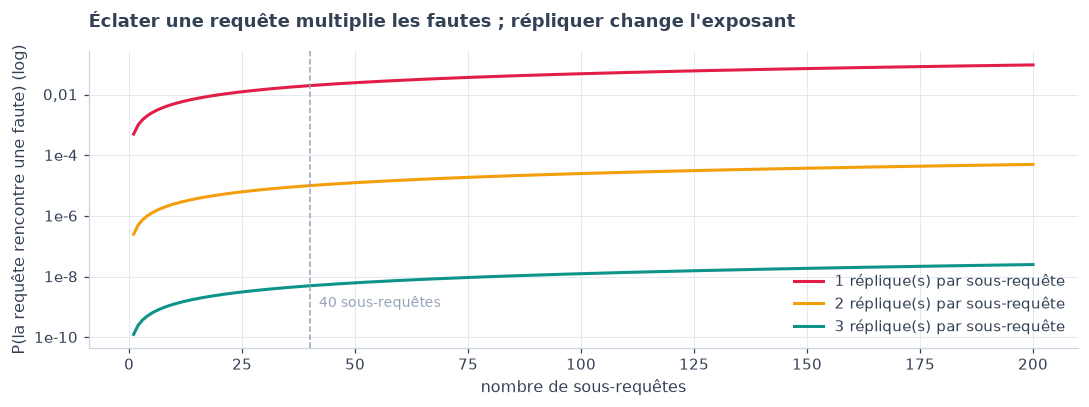

,P_formule,P_simulée,requêtes_par_jour
répliques,,,
1,1.9806e-02,1.9850e-02,8.5563e+06
2,1.0000e-05,1.2500e-05,4.3200e+03
3,5.0000e-09,0.0000e+00,2.1600e+00


In [2]:
lam = 2000 / (4 * 365)
p, n, debit = 5e-4, 40, 5000
rows = []
for r in (1, 2, 3):
    pr = 1 - (1 - p ** r) ** n
    panne = np.ones((400_000, n), bool)                    # Monte-Carlo : 400 000 requêtes
    for _ in range(r):                                     # une sous-requête échoue si ses r répliques sont en faute
        panne &= rng.random((400_000, n), dtype=np.float32) < p
    sim = np.mean(panne.any(axis=1))
    rows.append(dict(répliques=r, P_formule=pr, P_simulée=sim, requêtes_par_jour=pr * debit * 86_400))
R = pd.DataFrame(rows).set_index("répliques")
jours = rng.poisson(lam, 365 * 50)                         # 50 années simulées
print(f"pannes définitives : {lam:.2f}/jour ; semaines sans panne simulées : "
      f"{np.mean(jours[: (jours.size // 7) * 7].reshape(-1, 7).sum(axis=1) == 0):.5f} (théorie {math.exp(-7 * lam):.5f})")
fig, ax = plt.subplots(figsize=(10, 3.8))
fan = np.arange(1, 201)
for r, c in [(1, ROSE), (2, AMBER), (3, TEAL)]:
    ax.semilogy(fan, 1 - (1 - p ** r) ** fan, color=c, label=f"{r} réplique(s) par sous-requête")
ax.axvline(40, color=GRAY, ls="--", lw=1); ax.text(42, 1e-9, "40 sous-requêtes", fontsize=9, color=GRAY)
plain_log_axis(ax, "y")
ax.set_xlabel("nombre de sous-requêtes"); ax.set_ylabel("P(la requête rencontre une faute) (log)")
ax.set_title("Éclater une requête multiplie les fautes ; répliquer change l'exposant")
ax.legend()
plt.tight_layout(); plt.show()
R

La simulation confirme les formules pour 1 et 2 répliques (avec 3, l'événement est trop
rare pour 400 000 tirages : la simulation donne 0). La semaine sans panne est si rare que
même 50 années simulées n'en contiennent quasiment aucune.

> **À retenir.** À l'échelle d'un parc, les pannes définitives sont quotidiennes et une
> requête éclatée rencontre souvent une faute transitoire. La redondance des
> sous-requêtes ramène ce risque de quelques pourcents à quelques millionièmes.

## Exercice 8.2 : relances, idempotence et durée de rétention des identifiants

**Énoncé.** Un service de paiement reçoit des ordres « débiter 50 € ». Le client attend
la réponse 2 s, puis relance (au plus 3 relances).

1. Pour chacun des scénarios suivants, dire ce que voit le client et ce que devient le
   compte : (a) la requête se perd ; (b) le serveur tombe avant de traiter ; (c) la réponse
   se perd ; (d) le serveur est en pause 5 s puis traite et répond.
2. On ajoute un identifiant unique à chaque ordre ; le serveur mémorise les identifiants
   déjà traités pendant une durée de rétention $D$ puis les oublie. Pourquoi faut-il une
   rétention ? Quelle valeur minimale proposer ?
3. Mini-lab : simuler 3 000 ordres sur un réseau qui perd 5 % des messages et retarde
   parfois un message de 15 s ; mesurer les doubles débits selon $D$.

**Rappels.** Ce que l'émetteur ne peut pas savoir, relances et identifiants (cours 1,
section 2 ; section *Unreliable Networks*) ; délais arbitraires (*Network Faults in Practice*).

**Solution.**

*1.* Dans les quatre cas, le client voit la même chose : **pas de réponse en 2 s**. Il
relance. Le compte, lui : (a) n'est pas débité par la première requête, la relance le
débite une fois ; (b) idem si le serveur redémarre ; (c) **a été débité** par la première
requête, la relance le débite une **seconde** fois ; (d) **double débit** aussi : la
requête initiale est traitée après la relance. Sans identifiant, (c) et (d) sont des
doubles débits.

*2.* Le serveur ne peut pas garder les identifiants indéfiniment (mémoire). Mais s'il
oublie un identifiant alors qu'une copie de l'ordre circule encore (relance tardive ou
message retardé dans le réseau), cette copie sera exécutée une seconde fois. La
rétention doit couvrir la **fenêtre** pendant laquelle une copie peut arriver :
$D \geq$ (durée totale des relances) + (délai réseau maximal plausible). Ici, 3 relances
espacées de 2 s font 6 s, plus 15 s de retard possible : $D \geq 21$ s, et l'on prend de la
marge, car aucun délai réseau n'est vraiment borné.

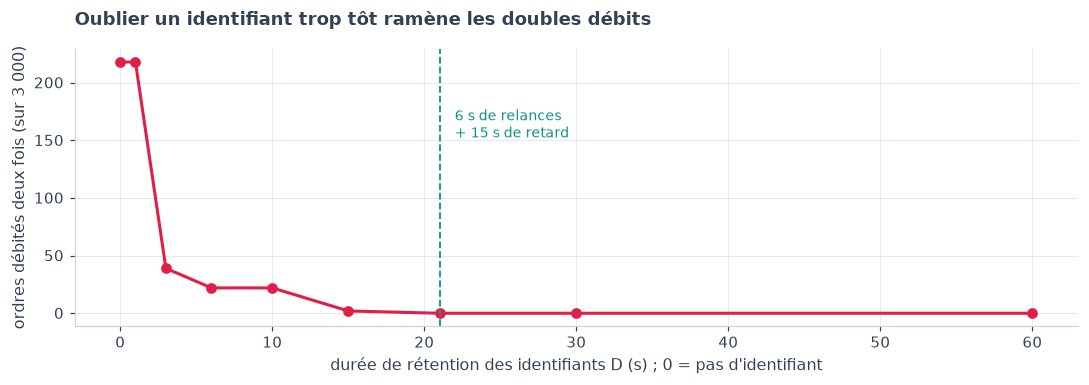

rétention_s,0,1,3,6,10,15,21,30,60
doubles_débits,218,218,39,22,22,2,0,0,0


In [3]:
class Banque(Node):
    def __init__(self, name, retention):
        super().__init__(name)
        self.retention, self.vus, self.debits = retention, {}, {}

    def on_message(self, src, msg):
        _, oid = msg
        for k in [k for k, t in self.vus.items() if self.now - t > self.retention]:
            del self.vus[k]                                  # oubli des vieux identifiants
        if oid not in self.vus:
            self.debits[oid] = self.debits.get(oid, 0) + 1
        self.vus[oid] = self.vus.get(oid, self.now)
        self.send(src, ("ok", oid))


class Payeur(Node):
    def __init__(self, name, n):
        super().__init__(name)
        self.n, self.ok = n, set()

    def on_start(self):
        for oid in range(self.n):
            self.set_timer(oid * 0.2, self.essai, oid, 0)

    def essai(self, oid, k):
        if oid in self.ok or k > 3:
            return
        self.send("banque", ("débiter 50", oid))
        self.set_timer(2.0, self.essai, oid, k + 1)

    def on_message(self, src, msg):
        self.ok.add(msg[1])


def latence(rng_, src, dst):
    return rng_.uniform(0.05, 0.6) + (15.0 if rng_.random() < 0.01 else 0.0)

rows = []
for D in [0, 1, 3, 6, 10, 15, 21, 30, 60]:
    net = Network(seed=5, latency=latence, drop=0.05)
    b = net.add(Banque("banque", D if D else -1))
    net.add(Payeur("client", 3000))
    net.run()
    doubles = sum(v >= 2 for v in b.debits.values())
    rows.append(dict(rétention_s=D, doubles_débits=doubles, mémoire_max=None))
Dd = pd.DataFrame(rows).drop(columns="mémoire_max")
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(Dd.rétention_s, Dd.doubles_débits, "o-", color=ROSE)
ax.axvline(21, color=TEAL, ls="--", lw=1.2); ax.text(22, Dd.doubles_débits.max() * 0.7, "6 s de relances\n+ 15 s de retard", color=TEAL, fontsize=9)
ax.set_xlabel("durée de rétention des identifiants D (s) ; 0 = pas d'identifiant")
ax.set_ylabel("ordres débités deux fois (sur 3 000)")
ax.set_title("Oublier un identifiant trop tôt ramène les doubles débits")
plt.tight_layout(); plt.show()
Dd.set_index("rétention_s").T

Sans identifiant, plus de deux cents ordres sont débités deux fois. Une rétention
courte supprime les doublons dus aux relances rapprochées, mais pas ceux dus aux
messages retardés de 15 s ; à partir d'une rétention qui couvre relances et retard, il
n'en reste plus.

> **À retenir.** Une relance n'est sûre que si l'opération est idempotente. Avec des
> identifiants de requête, la durée de rétention doit couvrir la fenêtre des relances
> **et** le pire retard réseau plausible.

## Exercice 8.3 : choisir un délai d'expiration face à une queue lourde

**Énoncé.** Dans un cluster de 50 nœuds, chaque nœud émet un battement toutes les 200 ms.
Le délai d'un battement vaut environ 2 ms, sauf avec probabilité $10^{-3}$ où il subit un
surcoût de Pareto : $P(\text{surcoût} > x) = (50/x)^{1{,}5}$ pour $x \geq 50$ ms. Un nœud
est soupçonné si aucun battement n'arrive pendant $T$. On veut **moins d'une fausse
déclaration de décès par jour** pour tout le cluster.

1. **Retards indépendants.** Chaque battement est retardé indépendamment des autres.
   Exprimer la probabilité $q(T)$ de fausse suspicion par intervalle. Quel $T$ faut-il ?
2. **Retards corrélés.** En réalité, une congestion retarde **tous** les paquets pendant
   un moment. On modélise : avec probabilité $10^{-3}$ par intervalle, un épisode de
   congestion de durée $D$ (même loi de Pareto) retient tous les battements jusqu'à sa
   fin. Que deviennent $q(T)$ et $T$ ?
3. Avec des retards corrélés, chaque nœud est surveillé par **5** observateurs et n'est
   déclaré mort que si **au moins 3** le soupçonnent. Quel $T$ suffit si les épisodes
   touchent les **liens** indépendamment ? Et s'ils touchent le **nœud** surveillé ?

**Rappels.** Délais non bornés, compromis du délai d'expiration, files d'attente (cours
2, sections 1 et 2 ; section *Timeouts and Unbounded Delays*) ; décisions par quorum
(cours 4, section 3).

**Solution.**

Intervalles par jour pour le cluster : $50 \times 86\,400 / 0{,}2 = 2{,}16 \times 10^7$ ;
l'objectif est donc $q(T) < 4{,}6 \times 10^{-8}$.

*1.* Si le battement $i$ arrive à l'heure, le battement $i+j$, émis $200j$ ms plus tard,
doit avoir un retard supérieur à $T - 200j$ pour que le silence dure $T$ : **tous** les
battements émis pendant $T$ doivent être en retard. Avec des retards indépendants,
$q(T) = \prod_{j \geq 1,\, 200j < T} P(d > T - 200j)$. Un battement en retard est vite
« rattrapé » par le suivant : pour $T \leq 400$ ms, un seul retard suffit et
$q(400) \approx 10^{-3} (50/200)^{1{,}5} = 1{,}25 \times 10^{-4}$, trop ; pour
$T = 500$ ms, il faut deux retards ($> 300$ et $> 100$ ms) :
$q \approx 6{,}8 \times 10^{-5} \times 3{,}5 \times 10^{-4} = 2{,}4 \times 10^{-8}$. Environ
**500 ms** suffisent.

*2.* Un épisode de durée $D$ crée un silence d'environ $D + 200$ ms :
$q(T) \approx 10^{-3} \left(\frac{50}{T - 200}\right)^{1{,}5}$. L'objectif impose
$T - 200 > 50 \times (4{,}6 \times 10^{-5})^{-2/3} \approx 39\,000$ ms : il faudrait attendre
**près de 40 secondes**. La corrélation des retards change tout.

*3.* Si les épisodes touchent les liens indépendamment, il faut 3 liens sur 5 en épisode
en même temps : $P \approx \binom{5}{3} q^3 = 10 q^3 < 4{,}6\times10^{-8}$, soit
$q < 1{,}7 \times 10^{-3}$, vrai pour **tout** $T \geq 250$ ms. Mais si c'est le **nœud
surveillé** qui cause l'épisode (pause, carte réseau saturée), les 5 observateurs voient
le même silence en même temps : le vote ne sert à rien et l'on retombe sur 40 s. Le
quorum protège des aléas des liens, pas de ceux du nœud.

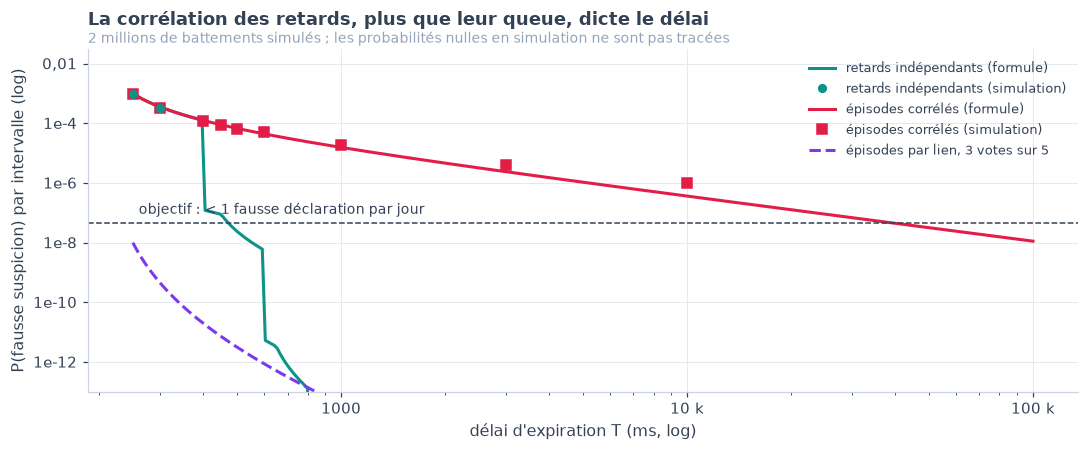

T minimal : retards indépendants ≈ 480 ms ; épisodes corrélés ≈ 39 s


T (ms),250,300,400,450,500,600,1000,3000,10000
indépendants simulé,0.0009,0.0003,0.0000,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00,0.0000e+00
indépendants formule,0.0010,0.0004,0.0001,8.9443e-08,2.4056e-08,5.5243e-09,2.0765e-18,8.8334e-72,3.7362e-286
corrélés simulé,0.0009,0.0003,0.0001,8.6000e-05,6.6500e-05,5.0500e-05,1.8500e-05,4.0000e-06,1.0000e-06
corrélés formule,0.0010,0.0004,0.0001,8.9443e-05,6.8041e-05,4.4194e-05,1.5625e-05,2.3863e-06,3.6443e-07


In [4]:
def p_retard(x):
    """P(délai d'un battement > x ms) : corps ~2 ms, plus 1e-3 de surcoût de Pareto."""
    x = np.asarray(x, dtype=float)
    corps = np.where(x < 2.0, 1.0, 0.0)
    return np.maximum(corps, 1e-3 * np.minimum(1.0, (50 / np.maximum(x, 1e-9)) ** 1.5))

def q_independant(T):
    return float(np.prod([p_retard(T - 200 * j) for j in range(1, int((T - 1e-9) // 200) + 1)]))

def q_correle(T):
    return 1e-3 * min(1.0, (50 / max(T - 200, 1e-9)) ** 1.5)

n_hb = 2_000_000
emis = np.arange(n_hb) * 200.0
spike = rng.random(n_hb) < 1e-3
duree = 50 * (rng.pareto(1.5, n_hb) + 1)
# retards indépendants : chaque battement porte son propre surcoût
arr_ind = np.sort(emis + 2.0 + np.where(spike, duree, 0))
# retards corrélés : un épisode retient tous les battements émis avant sa fin
fin = np.where(spike, emis + duree, -np.inf)
fin_courante = np.maximum.accumulate(fin)
arr_cor = np.sort(np.maximum(emis, fin_courante) + 2.0)
Ts = np.array([250, 300, 400, 450, 500, 600, 1000, 3000, 10_000])
sim_ind = [(np.diff(arr_ind) > T).mean() for T in Ts]
sim_cor = [(np.diff(arr_cor) > T).mean() for T in Ts]
cible = 1 / 2.16e7
TT = np.logspace(np.log10(250), np.log10(1e5), 300)
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.loglog(TT, [q_independant(t) for t in TT], color=TEAL, label="retards indépendants (formule)")
ax.loglog(Ts, sim_ind, "o", color=TEAL, ms=5, zorder=5, label="retards indépendants (simulation)")
ax.loglog(TT, [q_correle(t) for t in TT], color=ROSE, label="épisodes corrélés (formule)")
ax.loglog(Ts, sim_cor, "s", color=ROSE, label="épisodes corrélés (simulation)")
ax.loglog(TT, [10 * q_correle(t) ** 3 for t in TT], "--", color=VIOLET, label="épisodes par lien, 3 votes sur 5")
ax.axhline(cible, color=SLATE, ls="--", lw=1)
ax.text(260, cible * 2, "objectif : < 1 fausse déclaration par jour", color=SLATE, fontsize=9)
plain_log_axis(ax)
ax.set_ylim(1e-13, 3e-2)
ax.set_xlabel("délai d'expiration T (ms, log)"); ax.set_ylabel("P(fausse suspicion) par intervalle (log)")
ax.set_title("La corrélation des retards, plus que leur queue, dicte le délai")
subtitle(ax, "2 millions de battements simulés ; les probabilités nulles en simulation ne sont pas tracées")
ax.legend(loc="upper right", fontsize=8.5)
plt.tight_layout(); plt.show()
T_ind = next(t for t in range(250, 5000, 10) if q_independant(t) < cible)
T_cor = 200 + 50 * (cible / 1e-3) ** (-2 / 3)
print(f"T minimal : retards indépendants ≈ {T_ind} ms ; épisodes corrélés ≈ {T_cor / 1000:.0f} s")
pd.DataFrame({"T (ms)": Ts, "indépendants simulé": sim_ind, "indépendants formule": [q_independant(t) for t in Ts],
              "corrélés simulé": sim_cor, "corrélés formule": [q_correle(t) for t in Ts]}).set_index("T (ms)").T

Les simulations suivent les formules tant que les probabilités restent mesurables avec
2 millions de battements. Avec des retards indépendants, il suffit d'environ 500 ms ;
avec des épisodes corrélés, près de 40 s ; voter à trois sur cinq ramène à 250 ms si et
seulement si les épisodes frappent les liens indépendamment.

> **À retenir.** Ce qui fixe un délai d'expiration sûr, c'est moins la queue de la
> distribution des délais que leur **corrélation** : un retard isolé est rattrapé par le
> battement suivant, un épisode de congestion non. Plusieurs observateurs protègent des
> aléas des liens, pas de ceux du nœud surveillé.

## Exercice 8.4 : le détecteur phi accrual à la main

**Énoncé.** Un détecteur phi accrual a estimé que les intervalles entre battements suivent
une loi normale de moyenne $\mu = 1000$ ms et d'écart-type $\sigma = 100$ ms.

1. Calculer $\varphi$ lorsque 1 100, 1 300 et 1 500 ms se sont écoulées depuis le dernier
   battement.
2. Le seuil est $\varphi = 8$. Au bout de combien de temps de silence le nœud est-il
   suspecté ? Et si le réseau devient bruyant ($\sigma = 300$ ms) ?
3. Mini-lab : appliquer `ds.PhiAccrualDetector` à une trace dont l'écart-type passe de
   100 à 300 ms à mi-parcours ; comparer ses fausses suspicions à celles d'un délai fixe
   égal à la réponse de la question 2 pour $\sigma = 100$ ms.

**Rappels.** $\varphi(\Delta t) = -\log_{10} P(X > \Delta t)$ avec
$X \sim \mathcal{N}(\mu, \sigma^2)$ (cours 2, section 3 ; section *Timeouts and Unbounded Delays*).

**Solution.**

*1.* $z = (\Delta t - \mu)/\sigma$ vaut 1, 3 et 5 ; $P(Z > z)$ vaut $0{,}159$,
$1{,}35 \times 10^{-3}$ et $2{,}87 \times 10^{-7}$ ; d'où $\varphi \approx 0{,}80$, $2{,}87$ et
$6{,}54$. La suspicion croît très vite une fois la moyenne dépassée.

*2.* $\varphi = 8 \iff P(Z > z) = 10^{-8} \iff z \approx 5{,}61$ : suspicion après
$1000 + 5{,}61 \times 100 \approx 1\,561$ ms. Avec $\sigma = 300$ :
$1000 + 5{,}61 \times 300 \approx 2\,683$ ms. Le détecteur allonge de lui-même son délai
effectif quand la gigue augmente.

Δt = 1100 ms : z = 1, φ = 0.80
Δt = 1300 ms : z = 3, φ = 2.87
Δt = 1500 ms : z = 5, φ = 6.54
seuil φ = 8 : z = 5.61 ; délai effectif 1561 ms (σ = 100), 2684 ms (σ = 300)


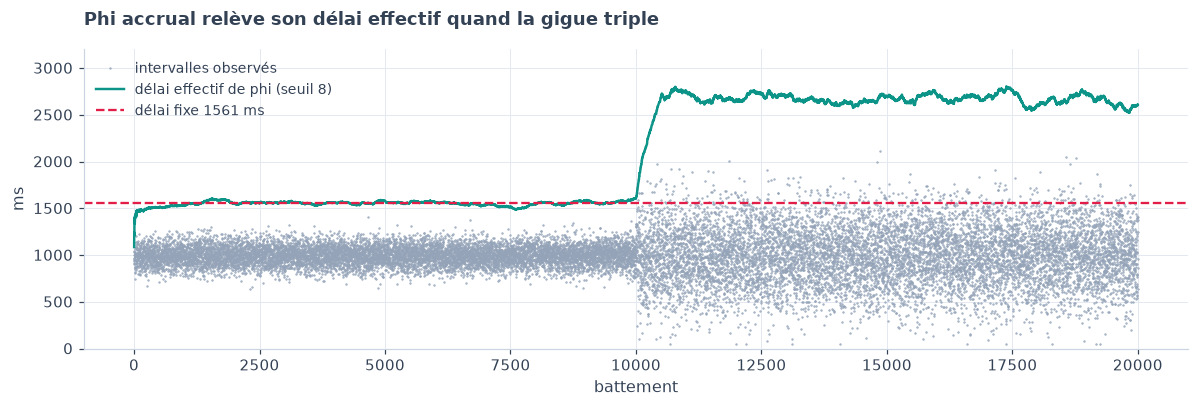

,phi accrual (seuil 8),délai fixe 1561 ms
"fausses suspicions, σ = 100",0,0
"fausses suspicions, σ = 300",1,267


In [5]:
N = NormalDist()
for dt in (1100, 1300, 1500):
    z = (dt - 1000) / 100
    print(f"Δt = {dt} ms : z = {z:.0f}, φ = {-math.log10(1 - N.cdf(z)):.2f}")
z8 = N.inv_cdf(1 - 1e-8)
print(f"seuil φ = 8 : z = {z8:.2f} ; délai effectif {1000 + z8 * 100:.0f} ms (σ = 100), {1000 + z8 * 300:.0f} ms (σ = 300)")

r4 = np.random.default_rng(7)
n4 = 20_000
inter = np.where(np.arange(n4) < n4 // 2, r4.normal(1000, 100, n4), r4.normal(1000, 300, n4)).clip(min=50)
arr = np.cumsum(inter)
det = ds.PhiAccrualDetector(window=500, min_std=10.0)
eff, fp_phi = [], np.zeros(n4, bool)
for k, t in enumerate(arr):
    if det.last is not None and det.intervals:
        mu, sd = det.stats()
        g = mu + sd * z8
        eff.append(g)
        fp_phi[k] = t - det.last > g
    else:
        eff.append(np.nan)
    det.heartbeat(t)
fixe = 1000 + z8 * 100
fp_fixe = np.r_[False, np.diff(arr) > fixe]
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.plot(np.diff(arr, prepend=0)[1:], ".", ms=1, color=GRAY, label="intervalles observés")
ax.plot(eff, color=TEAL, lw=1.6, label="délai effectif de phi (seuil 8)")
ax.axhline(fixe, color=ROSE, ls="--", lw=1.5, label=f"délai fixe {fixe:.0f} ms")
ax.set_xlabel("battement"); ax.set_ylabel("ms"); ax.set_ylim(0, 3200)
ax.set_title("Phi accrual relève son délai effectif quand la gigue triple")
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout(); plt.show()
pd.DataFrame({"phi accrual (seuil 8)": [fp_phi[: n4 // 2].sum(), fp_phi[n4 // 2:].sum()],
              f"délai fixe {fixe:.0f} ms": [fp_fixe[: n4 // 2].sum(), fp_fixe[n4 // 2:].sum()]},
             index=["fausses suspicions, σ = 100", "fausses suspicions, σ = 300"])

Dans la première moitié, les deux détecteurs sont équivalents (aucune fausse suspicion).
Quand la gigue triple, le délai fixe déclenche de nombreuses fausses suspicions (les
intervalles dépassent 1 561 ms dans environ 3 % des cas), alors que phi accrual a relevé son
délai effectif vers 2 700 ms en quelques centaines de battements et n'en produit
quasiment pas. Ce calcul suppose des intervalles normaux ; avec une queue lourde
(exercice 8.3), la loi normale sous-estime le risque.

> **À retenir.** $\varphi$ traduit un silence en probabilité d'erreur ; un seuil fixe sur
> $\varphi$ correspond à un délai effectif $\mu + z\sigma$ qui suit automatiquement la
> gigue du réseau.

## Exercice 8.5 : tampon de commutateur, perdre ou attendre

**Énoncé.** Le port de sortie d'un commutateur émet sur un lien à 10 Gbit/s des paquets de
1 500 octets. Les arrivées sont poissonniennes, de charge $\rho$, et le tampon contient
$K$ paquets (file M/M/1/K).

1. Calculer le temps d'émission d'un paquet, puis la probabilité de perte
   $P_K = \frac{(1-\rho)\rho^K}{1-\rho^{K+1}}$ pour $\rho \in \{0{,}8 ; 0{,}95\}$ et
   $K \in \{16 ; 64 ; 256\}$.
2. Quel est le délai maximal ajouté par un tampon plein de $K = 256$ paquets ? Commenter le
   compromis entre pertes et délai (et l'effet d'une perte sur TCP).
3. Le trafic réel arrive en **rafales**. Comparer, à charge 0,8, la perte prévue par la
   formule et celle de `ds.switch_port_sim` avec des rafales de 1 (trafic lisse) et de 8
   paquets en moyenne.

**Rappels.** Congestion et files des commutateurs, pertes qui se changent en délais de
retransmission (cours 2, section 2 ; section *Network congestion and queueing*) ; files
d'attente (chapitre 1, cours 3).

**Solution.**

*1.* $1500 \times 8 / 10^{10} = 1{,}2$ µs par paquet. Les pertes (tableau ci-dessous)
chutent exponentiellement avec $K$ à charge 0,8, mais beaucoup plus lentement à 0,95.

*2.* Un tampon plein de 256 paquets ajoute $256 \times 1{,}2 = 307$ µs, plus de mille fois
un aller-retour typique en baie. Un grand tampon évite des pertes (et donc des
retransmissions TCP de 200 ms et plus), mais impose un délai de file élevé à **tous** les
paquets quand il se remplit (le phénomène connu sous le nom de *bufferbloat*). Un petit
tampon garde des délais faibles mais perd davantage.

*3.* Voir la simulation : à charge égale, les rafales font déborder le tampon bien plus
souvent que ne le prédit la formule poissonnienne.

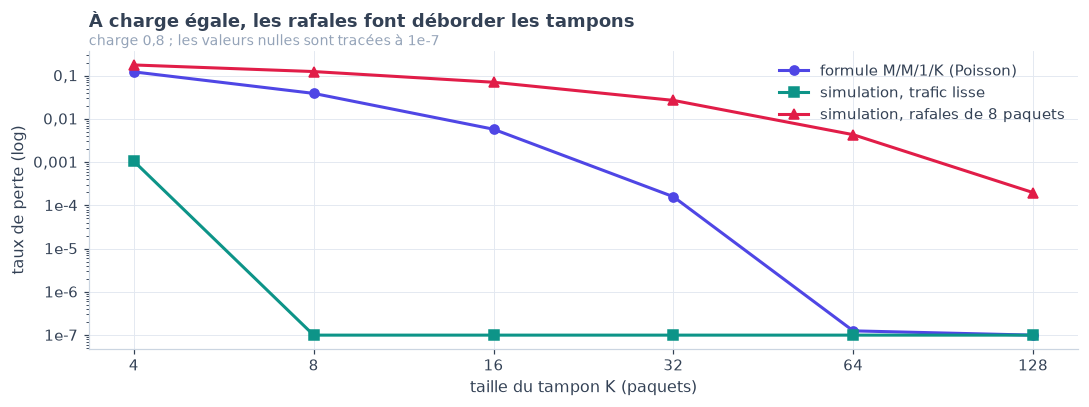

,ρ = 0.8,ρ = 0.95
K = 16,5.7592e-03,3.7819e-02
K = 64,1.2554e-07,1.9456e-03
K = 256,3.1050e-26,9.9132e-08


,formule,lisse,rafales
K,,,
4,1.2185e-01,0.001,0.1761
8,3.8756e-02,0.000,0.1239
16,5.7592e-03,0.000,0.0701
32,1.5856e-04,0.000,0.0267
64,1.2554e-07,0.000,0.0043
128,7.8804e-14,0.000,0.0002


In [6]:
def perte_mm1k(rho, K):
    return (1 - rho) * rho ** K / (1 - rho ** (K + 1))

T5 = pd.DataFrame({f"ρ = {rho}": {f"K = {K}": perte_mm1k(rho, K) for K in (16, 64, 256)} for rho in (0.8, 0.95)})
Ks = [4, 8, 16, 32, 64, 128]
rows = []
for K in Ks:
    lisse = ds.switch_port_sim(n_inputs=3, load=0.8, buffer=K, mean_burst=1.0, slots=150_000, seed=1)["drop_rate"]
    rafale = ds.switch_port_sim(n_inputs=3, load=0.8, buffer=K, mean_burst=8.0, slots=150_000, seed=1)["drop_rate"]
    rows.append(dict(K=K, formule=perte_mm1k(0.8, K), lisse=lisse, rafales=rafale))
S5 = pd.DataFrame(rows).set_index("K")
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.semilogy(S5.index, S5.formule.clip(lower=1e-7), "o-", color=INDIGO, label="formule M/M/1/K (Poisson)")
ax.semilogy(S5.index, S5.lisse.clip(lower=1e-7), "s-", color=TEAL, label="simulation, trafic lisse")
ax.semilogy(S5.index, S5.rafales.clip(lower=1e-7), "^-", color=ROSE, label="simulation, rafales de 8 paquets")
ax.set_xscale("log", base=2); ax.set_xticks(Ks); ax.set_xticklabels(Ks)
plain_log_axis(ax, "y")
ax.set_xlabel("taille du tampon K (paquets)"); ax.set_ylabel("taux de perte (log)")
ax.set_title("À charge égale, les rafales font déborder les tampons")
subtitle(ax, "charge 0,8 ; les valeurs nulles sont tracées à 1e-7")
ax.legend()
plt.tight_layout(); plt.show()
display(T5)
S5

Le trafic lisse (trois sources très régulières) ne perd presque rien, bien moins encore
que ne le prévoit la formule poissonnienne. En rafales, c'est l'inverse : à $K = 64$, on
perd 0,4 % des paquets contre $10^{-7}$ selon la formule, et il faut un tampon des dizaines
de fois plus grand pour la même perte. Les rafales, typiques du
trafic des centres de données, sont la vraie cause des pertes de congestion.

> **À retenir.** Un tampon échange des pertes contre du délai : plus grand, il perd moins
> mais allonge la file ; et le trafic en rafales déborde bien plus que ne le prévoit un
> modèle poissonnien.